### EXP 2

In [4]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import BaggingClassifier,AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score,classification_report
import pandas as pd

x, y = load_iris(return_X_y=True)

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=.3, random_state=42, stratify=y)

bagging = BaggingClassifier(
    DecisionTreeClassifier(), n_estimators=50, random_state=42)

boosting = AdaBoostClassifier(
    DecisionTreeClassifier(max_depth=1),
    n_estimators=50, random_state=42)

bagging.fit(x_train, y_train)
boosting.fit(x_train, y_train)

bagging_pred = bagging.predict(x_test)
boosting_pred = boosting.predict(x_test)

print("Bagging:", accuracy_score(y_test, bagging_pred))
print("Boosting:", accuracy_score(y_test, boosting_pred))

print("\nBagging Report")
print(classification_report(y_test, bagging_pred))

print("\nBoosting Report")
print(classification_report(y_test, boosting_pred))

Bagging: 0.9333333333333333
Boosting: 0.9333333333333333

Bagging Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        15
           1       0.88      0.93      0.90        15
           2       0.93      0.87      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.93      0.93        45
weighted avg       0.93      0.93      0.93        45


Boosting Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        15
           1       0.88      0.93      0.90        15
           2       0.93      0.87      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.93      0.93        45
weighted avg       0.93      0.93      0.93        45



### EXP 3

In [5]:
import pandas as pd

data = [
("sparrow","bird",1,1), ("eagle","bird",1,1),
("penguin","bird",0,0), ("bat","mammal",1,1),
("cat","mammal",0,1), ("butterfly","insect",1,1)
]

df = pd.DataFrame(data, columns=["name","type","has_wings","can_fly"])

print("Dataset:")
print(df)

print("\nCN2-like classification Rules:")
for c in ["type","has_wings"]:
    for v in df[c].unique():
        x = df[df[c] == v]
        if x.can_fly.all():
            print(f"IF {c}={v} THEN can_fly=1")

Dataset:
        name    type  has_wings  can_fly
0    sparrow    bird          1        1
1      eagle    bird          1        1
2    penguin    bird          0        0
3        bat  mammal          1        1
4        cat  mammal          0        1
5  butterfly  insect          1        1

CN2-like classification Rules:
IF type=mammal THEN can_fly=1
IF type=insect THEN can_fly=1
IF has_wings=1 THEN can_fly=1


### EXP 4

Cluster Centers
[[6.85384615 3.07692308 5.71538462 2.05384615]
 [5.006      3.428      1.462      0.246     ]
 [5.88360656 2.74098361 4.38852459 1.43442623]]


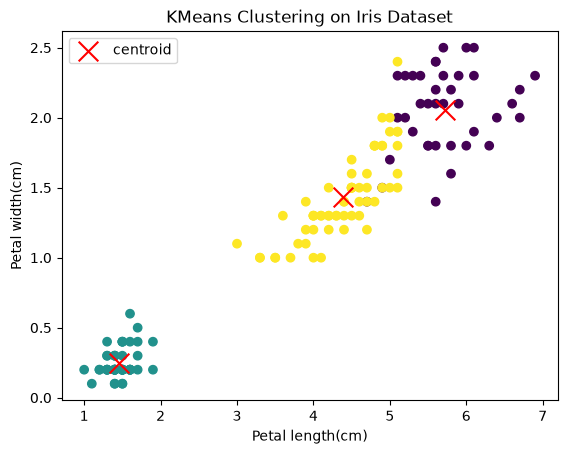

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import load_iris

iris = load_iris()
df = pd.DataFrame(iris.data)

model = KMeans(n_clusters=3, random_state=42)
mod_pred = model.fit_predict(df)

print("Cluster Centers")
print(model.cluster_centers_)

plt.scatter(df.iloc[:, 2], df.iloc[:, 3], c=mod_pred)
plt.scatter(model.cluster_centers_[:, 2],
            model.cluster_centers_[:, 3],
            c='red', marker='x', s=200, label='centroid')

plt.xlabel("Petal length(cm)")
plt.ylabel("Petal width(cm)")
plt.title("KMeans Clustering on Iris Dataset")
plt.legend()
plt.show()

### EXP 7

In [16]:
import pandas as pd
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination

d=pd.DataFrame([
['Sunny','Hot','High','Weak','No'],['Sunny','Hot','High','Strong','No'],
['Overcast','Hot','High','Weak','Yes'],['Rain','Mild','High','Weak','Yes'],
['Rain','Cool','Normal','Weak','Yes'],['Rain','Cool','Normal','Strong','No'],
['Overcast','Cool','Normal','Strong','Yes'],['Sunny','Mild','High','Weak','No'],
['Sunny','Cool','Normal','Weak','Yes'],['Rain','Mild','Normal','Weak','Yes'],
['Sunny','Mild','Normal','Strong','Yes'],['Overcast','Mild','High','Strong','Yes'],
['Overcast','Hot','Normal','Weak','Yes'],['Rain','Mild','High','Strong','No']
],columns=['Outlook','Temperature','Humidity','Wind','Play'])

m=DiscreteBayesianNetwork([
('Outlook','Play'),('Temperature','Play'),
('Humidity','Play'),('Wind','Play')])

m.fit(d)

q=VariableElimination(m).query(
    ['Play'],evidence={'Outlook':'Sunny','Humidity':'High'})

print(q)

+-----------+-------------+
| Play      |   phi(Play) |
+===========+=============+
| Play(No)  |      0.7653 |
+-----------+-------------+
| Play(Yes) |      0.2347 |
+-----------+-------------+


### EXP 8

In [18]:
import pandas as pd
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination

d=pd.DataFrame([
['Sunny','Hot','High','Weak','No'],['Sunny','Hot','High','Strong','No'],
['Overcast','Hot','High','Weak','Yes'],['Rain','Mild','High','Weak','Yes'],
['Rain','Cool','Normal','Weak','Yes'],['Rain','Cool','Normal','Strong','No'],
['Overcast','Cool','Normal','Strong','Yes'],['Sunny','Mild','High','Weak','No'],
['Sunny','Cool','Normal','Weak','Yes'],['Rain','Mild','Normal','Weak','Yes'],
['Sunny','Mild','Normal','Strong','Yes'],['Overcast','Mild','High','Strong','Yes'],
['Overcast','Hot','Normal','Weak','Yes'],['Rain','Mild','High','Strong','No']
],columns=['Outlook','Temperature','Humidity','Wind','Play'])

m=DiscreteBayesianNetwork([
('Outlook','Play'),('Temperature','Play'),
('Humidity','Play'),('Wind','Play')])

m.fit(d)
q=VariableElimination(m)

e=[
{'Outlook':'Sunny','Humidity':'High'},
{'Outlook':'Rain','Wind':'Weak'},
{'Outlook':'Overcast'},
{'Temperature':'Cool','Humidity':'Normal'},
{'Wind':'Strong'}]

for i,x in enumerate(e,1):
    print(f"\n{i}: P(Play | {x})")
    print(q.query(['Play'],evidence=x))


1: P(Play | {'Outlook': 'Sunny', 'Humidity': 'High'})
+-----------+-------------+
| Play      |   phi(Play) |
+===========+=============+
| Play(No)  |      0.7653 |
+-----------+-------------+
| Play(Yes) |      0.2347 |
+-----------+-------------+

2: P(Play | {'Outlook': 'Rain', 'Wind': 'Weak'})
+-----------+-------------+
| Play      |   phi(Play) |
+===========+=============+
| Play(No)  |      0.2143 |
+-----------+-------------+
| Play(Yes) |      0.7857 |
+-----------+-------------+

3: P(Play | {'Outlook': 'Overcast'})
+-----------+-------------+
| Play      |   phi(Play) |
+===========+=============+
| Play(No)  |      0.3418 |
+-----------+-------------+
| Play(Yes) |      0.6582 |
+-----------+-------------+

4: P(Play | {'Temperature': 'Cool', 'Humidity': 'Normal'})
+-----------+-------------+
| Play      |   phi(Play) |
+===========+=============+
| Play(No)  |      0.3112 |
+-----------+-------------+
| Play(Yes) |      0.6888 |
+-----------+-------------+

5: P(Play | 